# 01 · Exploratory Data Analysis: Human Mobility in Yogyakarta

Data sources:
1. JogjaPulse: aggregated, k-anonymised (k = 5) mobile-device presence for DIY, 1 Dec 2021 – 30 Apr 2022 ([Zenodo 10.5281/zenodo.23157460](https://doi.org/10.5281/zenodo.23157460), CC BY 4.0).
2. Google COVID-19 Community Mobility Reports: daily % change vs a Jan–Feb 2020 baseline, Special Region of Yogyakarta.

Questions covered:
1. What is in each file, and how complete is it?
2. How does the device panel change over time (the "panel decay"), and why must we normalise?
3. What are the temporal (hour/weekday) and spatial (500 m grid) patterns?
4. How representative are devices compared with the BPS population?
5. What do the daytime-visit (OD) flows look like?
6. What does Google's data show, and a first look at how it lines up with JogjaPulse.

Figures are saved to `reports/figures/eda_*.png`.

> A device is not a person. A missing row means fewer than 5 devices, not zero. Raw counts can't be compared across months.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from config import (CALENDAR_CSV, FIGURES as FIG, HALF_CELL_DEG, KAB_ORDER, LATTICE_STEPS_DEG,
                    PANEL_BREAKS, RAW_EXT, RAW_JP as RAW)
from build_features import calendar_by_date, weekday_deviation
from applied import baseline_days
EXT = RAW_EXT / "google_mobility"
FIG.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.width", 160, "display.max_columns", 20)

KAB_COLORS = dict(zip(KAB_ORDER, sns.color_palette("Set2", 5)))

# Holidays and notable dates (verified list in data/raw/external/calendar_2021_2022.csv)
cal = pd.read_csv(CALENDAR_CSV, parse_dates=["date"])
CAL_D = calendar_by_date(cal).set_index("date")   # holiday and panel-segment flags per day
EVENTS = (cal[~cal.name.str.contains("Muhammadiyah")]
          .assign(event=lambda d: d.name.str.replace(r" \(.*\)", "", regex=True))[["date", "event"]])

def savefig(fig, name):
    fig.savefig(FIG / f"eda_{name}.png")

def mark_events(ax, breaks=True, labels=True):
    for _, r in EVENTS.iterrows():
        ax.axvline(r.date, color="grey", ls=":", lw=1, zorder=0)
        if labels:
            ax.text(r.date, 1.01, r.event, rotation=45, fontsize=7, color="dimgrey",
                    transform=ax.get_xaxis_transform(), ha="left", va="bottom")
    if breaks:
        for b in PANEL_BREAKS:
            ax.axvline(b, color="crimson", ls="--", lw=1.2, zorder=0)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%Y"))

## 1. Load data

In [2]:
hourly = pd.read_csv(RAW / "presence_kapanewon_hourly.csv", parse_dates=["date"])
grid = pd.read_csv(RAW / "presence_cell500m_daily.csv", parse_dates=["date"])
od = pd.read_csv(RAW / "od_home_visits_kapanewon_monthly.csv")
od_homes = pd.read_csv(RAW / "od_origin_homes_monthly.csv")
pop = pd.read_csv(RAW / "home_maids_vs_population_kapanewon.csv")
night = pd.read_csv(RAW / "validation_night_presence_kapanewon.csv")
tier1 = pd.read_csv(RAW / "tier1_summary.csv")
od_sum = pd.read_csv(RAW / "od_summary.csv")
google = pd.read_csv(EXT / "google_mobility_diy.csv", parse_dates=["date"])

google = google.rename(columns=lambda c: c.replace("_percent_change_from_baseline", ""))
GCATS = ["retail_and_recreation", "grocery_and_pharmacy", "parks",
         "transit_stations", "workplaces", "residential"]
google = google.loc[google.date.between("2021-12-01", "2022-04-30"), ["date"] + GCATS]

hourly["weekday"] = hourly.date.dt.day_name()
hourly["is_weekend"] = hourly.date.dt.day_of_week >= 5

files = {"presence_kapanewon_hourly": hourly, "presence_cell500m_daily": grid,
         "od_home_visits_kapanewon_monthly": od, "od_origin_homes_monthly": od_homes,
         "home_maids_vs_population_kapanewon": pop,
         "validation_night_presence_kapanewon": night, "google_mobility_diy": google}
pd.DataFrame({name: {"rows": len(df), "columns": df.shape[1],
                     "missing cells": int(df.isna().sum().sum())}
              for name, df in files.items()}).T

,rows,columns,missing cells
presence_kapanewon_hourly,230418,10,0
presence_cell500m_daily,183548,7,0
od_home_visits_kapanewon_monthly,9894,11,0
od_origin_homes_monthly,390,8,0
home_maids_vs_population_kapanewon,78,5,0
validation_night_presence_kapanewon,156,7,0
google_mobility_diy,151,7,0


In [3]:
hourly.head()

,kab_code,kab_kota,kapanewon_code,kapanewon,date,hour,n_maids,n_pings,weekday,is_weekend
0,34.01,KULON PROGO,34.01.01,TEMON,2021-12-01,0,16,66,Wednesday,False
1,34.01,KULON PROGO,34.01.02,WATES,2021-12-01,0,58,101,Wednesday,False
2,34.01,KULON PROGO,34.01.03,PANJATAN,2021-12-01,0,11,32,Wednesday,False
3,34.01,KULON PROGO,34.01.04,GALUR,2021-12-01,0,9,50,Wednesday,False
4,34.01,KULON PROGO,34.01.05,LENDAH,2021-12-01,0,14,74,Wednesday,False


In [4]:
hourly[["n_maids", "n_pings"]].describe().round(1)

,n_maids,n_pings
count,230418.0,230418.0
mean,72.0,191.4
std,124.2,369.3
min,5.0,5.0
25%,12.0,28.0
50%,29.0,72.0
75%,77.0,201.0
max,2506.0,10210.0


## 2. Data quality and coverage

### 2.1 Privacy suppression (k = 5)
Rows with fewer than 5 devices were removed before publication. This shows how much of each product is missing.

In [5]:
supp = tier1[["product", "rows_total", "rows_published", "rows_suppressed_pct",
              "maid_presence_suppressed_pct", "n_cells_published"]]
display(supp)
display(od_sum)

,product,rows_total,rows_published,rows_suppressed_pct,maid_presence_suppressed_pct,n_cells_published
0,A_cell500m_daily,518176,183548,64.6,6.6,5715
1,B_kapanewon_hourly,273979,230418,15.9,0.7,78


,k,min_nights,od_rows_total,od_rows_published,od_rows_suppressed_pct,inter_zonal_flow_kept_pct,origin_rows_published
0,5,2,19263,9894,48.6,95.3,390


Reading the table:
- 500 m grid: 64.6% of cell-days are suppressed, but only 6.6% of device presence is lost. The suppressed cells are the near-empty ones.
- Kapanewon-hourly: 0.7% of presence is lost.
- OD: about half the flow rows are suppressed, but 95% of the inter-zonal flow volume is kept.

### 2.2 Completeness in time and space

In [6]:
cov = pd.DataFrame({
    "hourly: days": [hourly.date.nunique()],
    "hourly: kapanewon (by code)": [hourly.kapanewon_code.nunique()],
    "hourly: kapanewon (by name)": [hourly.kapanewon.nunique()],
    "hourly: kapanewon-hours present (%)": [round(100 * len(hourly) /
        (hourly.date.nunique() * 24 * hourly.kapanewon_code.nunique()), 1)],
    "grid: days": [grid.date.nunique()],
    "grid: cells ever published": [grid.cell_id.nunique()],
    "google: days": [google.date.nunique()],
    "google: missing values": [int(google[GCATS].isna().sum().sum())],
}).T.rename(columns={0: "value"})
cov

,value
hourly: days,151.0
hourly: kapanewon (by code),78.0
hourly: kapanewon (by name),77.0
hourly: kapanewon-hours present (%),81.5
grid: days,151.0
grid: cells ever published,5715.0
google: days,151.0
google: missing values,0.0


In [7]:
# Kapanewon names are NOT unique: the same name can exist in two kabupaten
names = hourly[["kab_kota", "kapanewon", "kapanewon_code"]].drop_duplicates()
dup = names[names.kapanewon.duplicated(keep=False)]
display(dup)

# Name matching between files must use (kabupaten, kapanewon), not the name alone
hourly_keys = set(zip(names.kab_kota, names.kapanewon))
pop_keys = set(zip(pop.KAB_KOTA, pop.KEC_KAPN))
print("In pop file, not in hourly:", sorted(pop_keys - hourly_keys))
print("In hourly, not in pop file:", sorted(hourly_keys - pop_keys))

,kab_kota,kapanewon,kapanewon_code
19,BANTUL,JETIS,34.02.09
54,YOGYAKARTA,JETIS,34.71.02


In pop file, not in hourly: []
In hourly, not in pop file: []


Join rule: the hourly file has 78 kapanewon codes but only 77 unique names, because one name is shared by two kabupaten. Always join on `(kab_kota, kapanewon)` or on the code, never on the name alone.

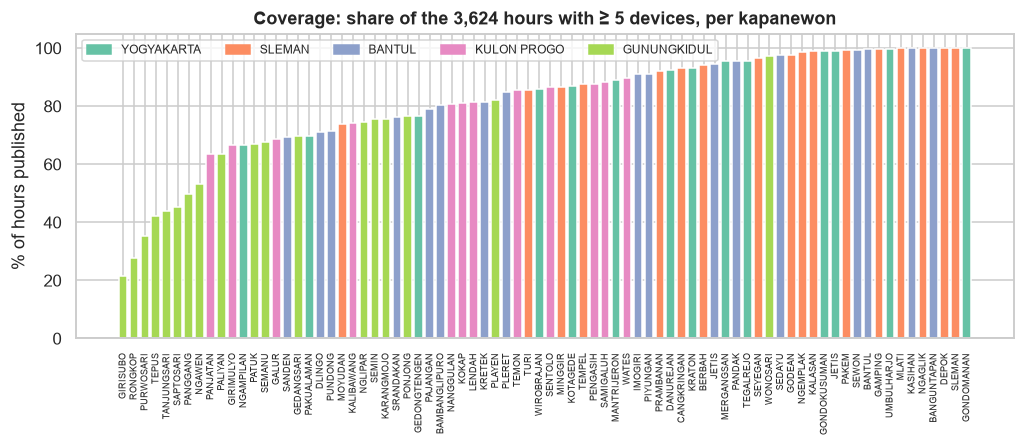

,kab_kota,kapanewon,pct_hours_published
18,GUNUNGKIDUL,GIRISUBO,21.633554
28,GUNUNGKIDUL,RONGKOP,27.593819
27,GUNUNGKIDUL,PURWOSARI,35.430464
33,GUNUNGKIDUL,TEPUS,42.190949
32,GUNUNGKIDUL,TANJUNGSARI,43.901766
29,GUNUNGKIDUL,SAPTOSARI,45.419426
23,GUNUNGKIDUL,PANGGANG,49.834437
20,GUNUNGKIDUL,NGAWEN,53.090508


In [8]:
# How many kapanewon-hours are published per kapanewon? (low = often < 5 devices)
pub = (hourly.groupby(["kab_kota", "kapanewon"]).size()
       / (hourly.date.nunique() * 24) * 100).rename("pct_hours_published").reset_index()
fig, ax = plt.subplots(figsize=(11, 3.6))
pub = pub.sort_values("pct_hours_published")
ax.bar(range(len(pub)), pub.pct_hours_published,
       color=pub.kab_kota.map(KAB_COLORS))
ax.set_xticks(range(len(pub)), pub.kapanewon, rotation=90, fontsize=6)
ax.set_ylabel("% of hours published")
ax.set_title("Coverage: share of the 3,624 hours with ≥ 5 devices, per kapanewon")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in KAB_COLORS.values()],
          labels=KAB_ORDER, ncol=5, fontsize=8, loc="upper left")
savefig(fig, "coverage_kapanewon")
plt.show()
pub.head(8)

## 3. Panel decay: why we must normalise

JogjaPulse counts devices seen by the data provider, and that sample changes over time. Two daily totals track it:
- Hourly presence total: the sum over all kapanewon and hours of `n_maids` (device-hours).
- Night presence: the mean over 00–05 of the summed `n_maids`. At night devices barely move, so this tracks the size of the active panel. It is lower than the README's distinct-devices-per-day figure because many devices don't ping every night hour.

The red dashed lines are the panel breaks reported in the README (1 Jan, 16 Feb 2022).

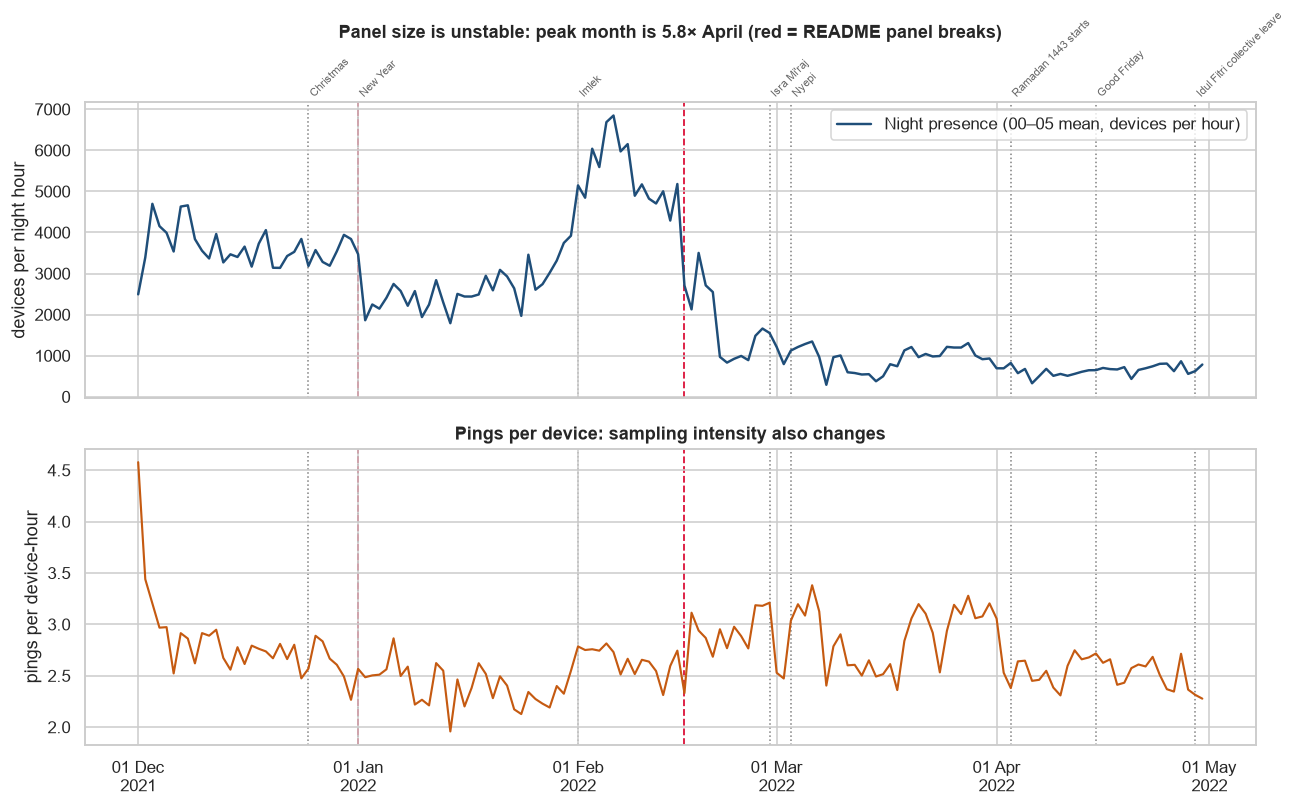

,mean night presence / hour
date,
2021-12,3634.0
2022-01,2651.0
2022-02,3723.0
2022-03,934.0
2022-04,644.0


In [9]:
by_dh = hourly.groupby(["date", "hour"]).n_maids.sum().unstack()
daily = pd.DataFrame({
    "presence_total": by_dh.sum(axis=1),
    "night_devices": by_dh[[0, 1, 2, 3, 4, 5]].mean(axis=1),
    "grid_presence": grid.groupby("date").n_maids.sum(),
})
daily["pings"] = hourly.groupby("date").n_pings.sum()
daily["pings_per_device"] = daily.pings / hourly.groupby("date").n_maids.sum()

monthly = daily.groupby(daily.index.to_period("M")).night_devices.mean().round(0)
shrink = monthly.max() / monthly.iloc[-1]

fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True)
ax = axes[0]
ax.plot(daily.index, daily.night_devices, color="#1f4e79", lw=1.6, label="Night presence (00–05 mean, devices per hour)")
ax.set_ylabel("devices per night hour")
ax.set_title(f"Panel size is unstable: peak month is {shrink:.1f}× April (red = README panel breaks)", pad=42)
mark_events(ax)
ax.legend(loc="upper right")
ax = axes[1]
ax.plot(daily.index, daily.pings_per_device, color="#c55a11", lw=1.4)
ax.set_ylabel("pings per device-hour")
ax.set_title("Pings per device: sampling intensity also changes")
mark_events(ax, labels=False)
fig.tight_layout()
savefig(fig, "panel_decay")
plt.show()

monthly.to_frame("mean night presence / hour")

Raw counts can't be compared across months. The usual fix is shares: a kapanewon's or cell's count divided by the DIY total for the same day or hour. The next figure tests whether shares are enough.

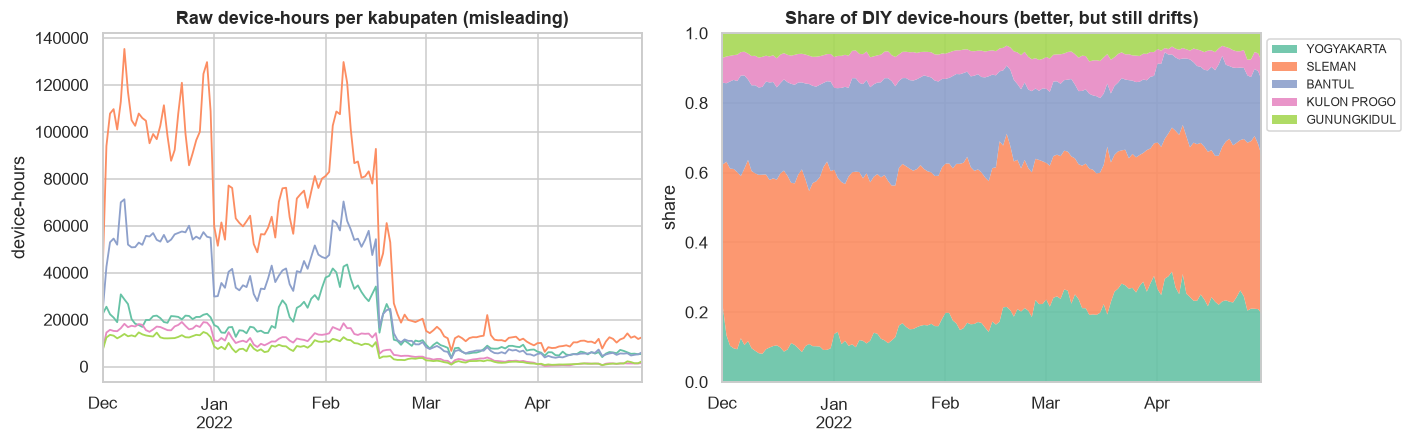

kab_kota,YOGYAKARTA,SLEMAN,BANTUL,KULON PROGO,GUNUNGKIDUL
date,,,,,
2021-12,0.105,0.493,0.261,0.079,0.062
2022-01,0.139,0.458,0.266,0.080,0.058
2022-02,0.187,0.443,0.242,0.075,0.053
2022-03,0.245,0.399,0.208,0.085,0.063
2022-04,0.245,0.443,0.222,0.041,0.049


In [10]:
# Do shares remove the panel effect?
hourly["daily_total"] = hourly.groupby("date").n_maids.transform("sum")
kab_share = (hourly.groupby(["date", "kab_kota"]).n_maids.sum()
             / hourly.groupby("date").n_maids.sum()).unstack()[KAB_ORDER]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
kab_raw = hourly.groupby(["date", "kab_kota"]).n_maids.sum().unstack()[KAB_ORDER]
kab_raw.plot(ax=axes[0], color=[KAB_COLORS[k] for k in KAB_ORDER], lw=1.2, legend=False)
axes[0].set_title("Raw device-hours per kabupaten (misleading)")
axes[0].set_ylabel("device-hours")
kab_share.plot.area(ax=axes[1], color=[KAB_COLORS[k] for k in KAB_ORDER], lw=0, alpha=.9)
axes[1].set_title("Share of DIY device-hours (better, but still drifts)")
axes[1].set_ylabel("share"); axes[1].set_ylim(0, 1)
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize=8)
for ax in axes:
    ax.set_xlabel("")
fig.tight_layout()
savefig(fig, "raw_vs_share")
plt.show()
kab_share.groupby(kab_share.index.to_period("M")).mean().round(3)

Shares help but don't fix everything. Kota Yogyakarta's share more than doubles from December to March/April, which is too large a change to be behaviour. The likely cause is that the panel's geographic make-up changed, with the remaining devices more urban.

Rule for the project:
- Compare places within the same day (shares are fine).
- Compare across time only as a deviation from the same weekday a few weeks around (local baseline), or within one panel segment: Dec / 1 Jan–15 Feb / 16 Feb–Apr.

## 4. Temporal patterns

### 4.1 Daily rhythm: hour × weekday
Each cell is that hour's share of the day's device presence, averaged over the whole period. Shares remove the panel-size effect.

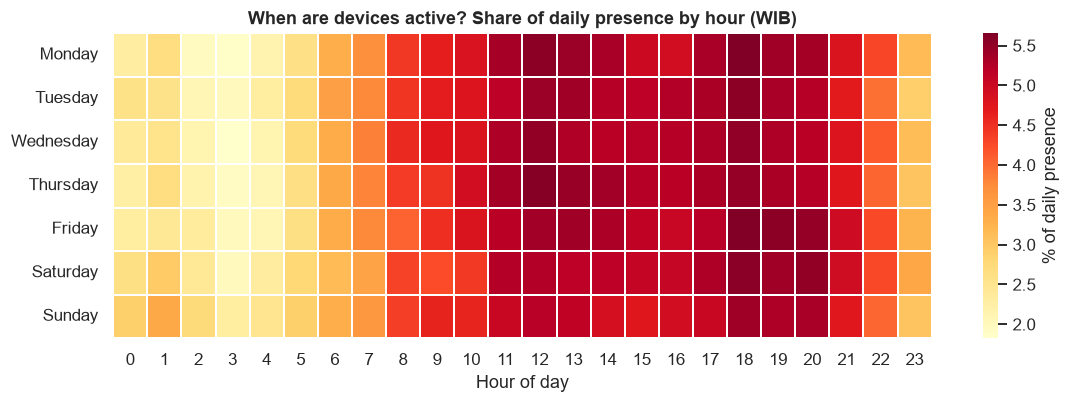

In [11]:
hourly["hour_share"] = hourly.n_maids / hourly.daily_total
hw = (hourly.groupby(["date", "hour"]).hour_share.sum().reset_index()
      .assign(weekday=lambda d: d.date.dt.day_name()))
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
heat = hw.groupby(["weekday", "hour"]).hour_share.mean().unstack().loc[order] * 100

fig, ax = plt.subplots(figsize=(12, 3.6))
sns.heatmap(heat, cmap="YlOrRd", ax=ax, cbar_kws={"label": "% of daily presence"},
            linewidths=.3, linecolor="white")
ax.set_title("When are devices active? Share of daily presence by hour (WIB)")
ax.set_xlabel("Hour of day"); ax.set_ylabel("")
savefig(fig, "heatmap_hour_weekday")
plt.show()

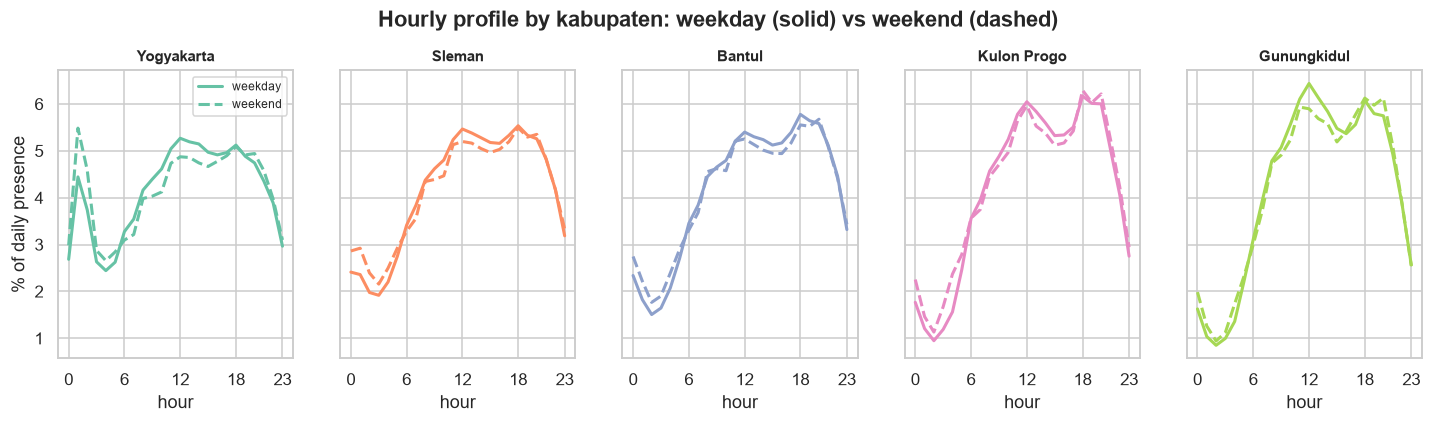

In [12]:
# Hourly profile per kabupaten, weekday vs weekend
hourly["kab_day_total"] = hourly.groupby(["date", "kab_kota"]).n_maids.transform("sum")
prof = (hourly.groupby(["date", "kab_kota", "hour", "is_weekend"]).n_maids.sum()
        / hourly.groupby(["date", "kab_kota", "hour", "is_weekend"]).kab_day_total.first())
prof = prof.groupby(["kab_kota", "is_weekend", "hour"]).mean().rename("share").reset_index()

fig, axes = plt.subplots(1, 5, figsize=(16, 3.4), sharey=True)
for ax, kab in zip(axes, KAB_ORDER):
    for wk, ls in [(False, "-"), (True, "--")]:
        d = prof[(prof.kab_kota == kab) & (prof.is_weekend == wk)]
        ax.plot(d.hour, d.share * 100, ls=ls, color=KAB_COLORS[kab], lw=2,
                label="weekend" if wk else "weekday")
    ax.set_title(kab.title(), fontsize=10)
    ax.set_xticks([0, 6, 12, 18, 23])
    ax.set_xlabel("hour")
axes[0].set_ylabel("% of daily presence")
axes[0].legend(fontsize=8)
fig.suptitle("Hourly profile by kabupaten: weekday (solid) vs weekend (dashed)", fontweight="bold", y=1.04)
savefig(fig, "profile_kabupaten")
plt.show()

### 4.2 Weekly cycle and holidays
Daily share of DIY presence in Kota Yogyakarta (urban core) and Gunungkidul (beaches, tourism). Holidays are dotted lines.

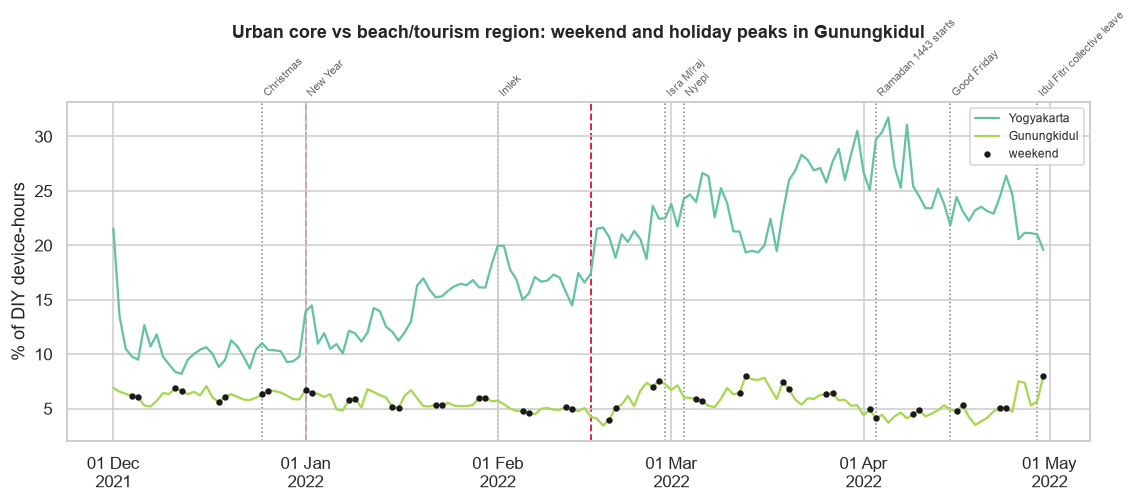

In [13]:
fig, ax = plt.subplots(figsize=(12, 4))
for kab in ["YOGYAKARTA", "GUNUNGKIDUL"]:
    ax.plot(kab_share.index, kab_share[kab] * 100, color=KAB_COLORS[kab], lw=1.5, label=kab.title())
wkend = kab_share.index[kab_share.index.day_of_week >= 5]
ax.scatter(wkend, kab_share.loc[wkend, "GUNUNGKIDUL"] * 100, s=10, color="k", zorder=3, label="weekend")
mark_events(ax)
ax.set_ylabel("% of DIY device-hours")
ax.set_title("Urban core vs beach/tourism region: weekend and holiday peaks in Gunungkidul", pad=42)
ax.legend(loc="upper right", fontsize=8)
savefig(fig, "share_city_vs_gunungkidul")
plt.show()

## 5. Spatial patterns (500 m grid)

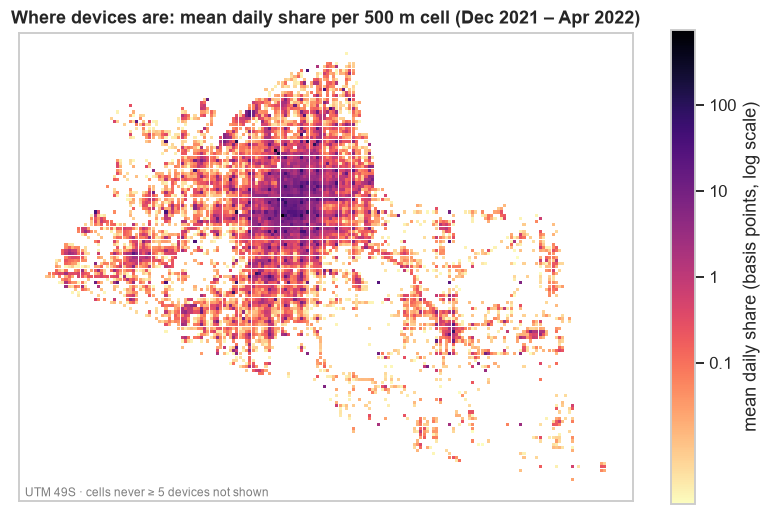

In [14]:
N_DAYS = grid.date.nunique()
grid["day_total"] = grid.groupby("date").n_maids.transform("sum")
grid["share"] = grid.n_maids / grid.day_total
cells = (grid.groupby(["cell_id", "x_min_utm", "y_min_utm", "centroid_lon", "centroid_lat"])
         .agg(share_sum=("share", "sum"), days_published=("date", "nunique"))
         .reset_index())
# mean over ALL days (unpublished days count as ~0), so rarely-seen cells don't rank high
cells["mean_share"] = cells.share_sum / N_DAYS
cells["mean_share_bp"] = cells.mean_share * 1e4   # basis points (0.01 %)

fig, ax = plt.subplots(figsize=(9, 8))
ax.grid(False)
sc = ax.scatter(cells.x_min_utm + 250, cells.y_min_utm + 250, c=np.log10(cells.mean_share_bp),
                s=4, marker="s", cmap="magma_r", linewidths=0)
ax.set_aspect("equal")
ax.set_xticks([]); ax.set_yticks([])
cb = fig.colorbar(sc, ax=ax, shrink=.7)
ticks = [-1, 0, 1, 2]
cb.set_ticks(ticks); cb.set_ticklabels([f"{10**t:g}" for t in ticks])
cb.set_label("mean daily share (basis points, log scale)")
ax.set_title("Where devices are: mean daily share per 500 m cell (Dec 2021 – Apr 2022)")
ax.text(0.01, 0.01, "UTM 49S · cells never ≥ 5 devices not shown", transform=ax.transAxes, fontsize=8, color="grey")
savefig(fig, "grid_presence_map")
plt.show()

### 5.1 Data artifact: coordinate "lattice" hotspots

The map shows isolated very dark cells on a regular pattern. Many of the top cells sit on round coordinates (−7.80°/110.30°, −7.70°/110.40°, …). This pattern fits pings whose coordinates were stored with low precision (rounded to 0.1° or 0.05°), which then all fall into the same cell. Below we flag cells that contain a 0.1° or 0.05° lattice point and measure how much presence they hold.

In [15]:
def on_lattice(step):
    dist = lambda v: np.abs(v / step - np.round(v / step)) * step
    return (dist(cells.centroid_lat) < HALF_CELL_DEG) & (dist(cells.centroid_lon) < HALF_CELL_DEG)

rows = []
for step in [0.1, 0.05, 0.01]:
    m = on_lattice(step)
    rows.append({"lattice step (°)": step, "cells": int(m.sum()),
                 "% of cells": round(100 * m.mean(), 2),
                 "% of all presence": round(100 * cells.mean_share[m].sum(), 1),
                 "mean share vs other cells": f"{cells.mean_share[m].mean() / cells.mean_share[~m].mean():.1f}×"})
display(pd.DataFrame(rows))

cells["lattice_artifact"] = np.logical_or.reduce([on_lattice(s) for s in LATTICE_STEPS_DEG])  # same rule as src/clean.py
print(f"Flagged {cells.lattice_artifact.sum()} cells as lattice artifacts "
      f"({100 * cells.loc[cells.lattice_artifact, 'mean_share'].sum():.1f}% of presence)")

,lattice step (°),cells,% of cells,% of all presence,mean share vs other cells
0,0.10,25,0.44,8.2,20.4×
1,0.05,70,1.22,8.6,7.6×
2,0.01,1182,20.68,29.2,1.6×


Flagged 70 cells as lattice artifacts (8.6% of presence)


Result: 1.2% of cells (those on 0.1° and 0.05° lattice points) hold 8.6% of all presence, 7–20× a typical cell. These are likely not real hotspots. The cells are flagged `lattice_artifact` and excluded from hotspot and holiday analyses (notebook 04); `src/clean.py` applies the same rule. This doesn't affect the kapanewon-level files much, because a whole kapanewon is much larger than the rounding error. They are still affected slightly: the rounded pings land in whichever kapanewon contains the lattice point.

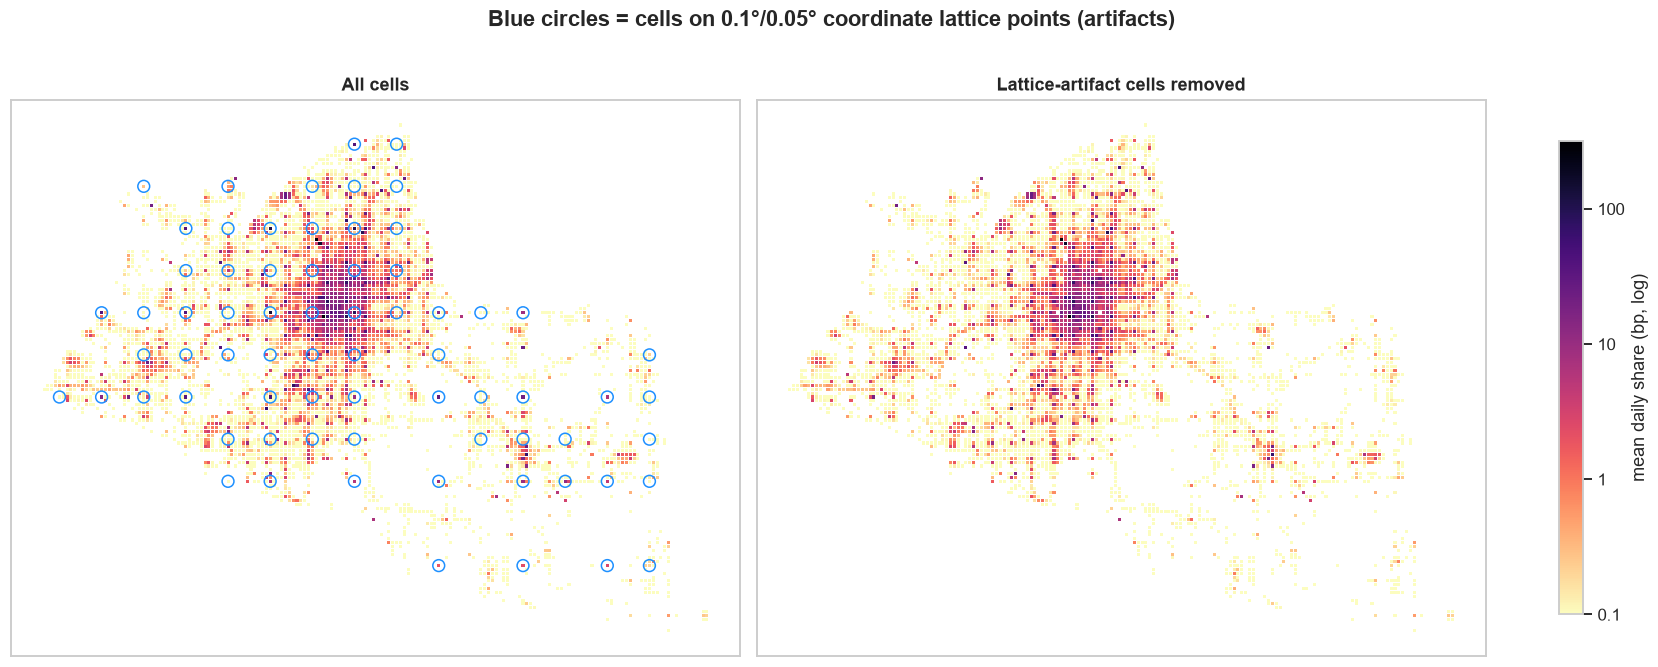

In [16]:
clean_cells = cells[~cells.lattice_artifact]
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), layout="constrained")
for ax, data, title in [(axes[0], cells, "All cells"), (axes[1], clean_cells, "Lattice-artifact cells removed")]:
    ax.grid(False)
    sc = ax.scatter(data.x_min_utm + 250, data.y_min_utm + 250, c=np.log10(data.mean_share_bp),
                    s=4, marker="s", cmap="magma_r", linewidths=0, vmin=-1, vmax=2.5)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(title)
art = cells[cells.lattice_artifact]
axes[0].scatter(art.x_min_utm + 250, art.y_min_utm + 250, s=60, facecolors="none", edgecolors="dodgerblue", lw=1)
cb = fig.colorbar(sc, ax=axes, shrink=.7)
cb.set_ticks([-1, 0, 1, 2]); cb.set_ticklabels(["0.1", "1", "10", "100"])
cb.set_label("mean daily share (bp, log)")
fig.suptitle("Blue circles = cells on 0.1°/0.05° coordinate lattice points (artifacts)", fontweight="bold")
savefig(fig, "grid_lattice_artifacts")
plt.show()

In [17]:
# Top 15 real hotspots (artifacts removed); no polygons yet, so give coordinates + a map link
top = clean_cells.nlargest(15, "mean_share")[["cell_id", "centroid_lat", "centroid_lon", "mean_share_bp", "days_published"]]
top["maps_link"] = "https://maps.google.com/?q=" + top.centroid_lat.round(5).astype(str) + "," + top.centroid_lon.round(5).astype(str)
top.round(5)

,cell_id,centroid_lat,centroid_lon,mean_share_bp,days_published,maps_link
2790,E859_N18274,-7.80461,110.36283,751.30256,151,"https://maps.google.com/?q=-7.80461,110.36283"
2663,E857_N18294,-7.71414,110.35390,328.78445,151,"https://maps.google.com/?q=-7.71414,110.3539"
2734,E858_N18293,-7.71867,110.35843,169.79776,151,"https://maps.google.com/?q=-7.71867,110.35843"
3548,E869_N18296,-7.70518,110.40832,99.96849,151,"https://maps.google.com/?q=-7.70518,110.40832"
3235,E865_N18274,-7.80465,110.39004,96.83412,151,"https://maps.google.com/?q=-7.80465,110.39004"
2871,E860_N18278,-7.78652,110.36739,85.94421,151,"https://maps.google.com/?q=-7.78652,110.36739"
2168,E851_N18256,-7.88596,110.32642,82.85231,143,"https://maps.google.com/?q=-7.88596,110.32642"
3244,E865_N18283,-7.76394,110.39010,74.61186,151,"https://maps.google.com/?q=-7.76394,110.3901"
3260,E865_N18299,-7.69158,110.39020,71.76081,110,"https://maps.google.com/?q=-7.69158,110.3902"
2876,E860_N18283,-7.76391,110.36743,71.27946,151,"https://maps.google.com/?q=-7.76391,110.36743"


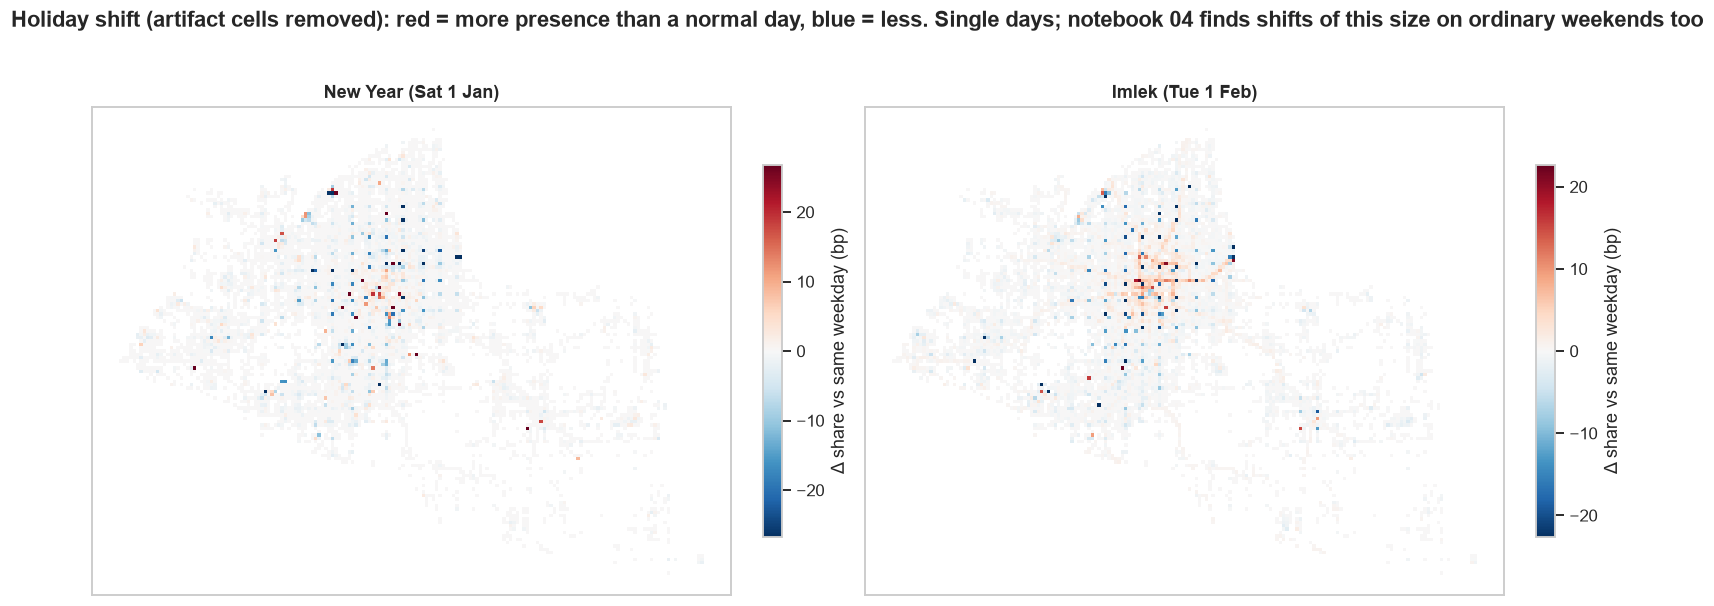

In [18]:
# Where does presence shift on holidays? Holiday share minus the mean share on the same weekday 1 and 2 weeks
# before and after, within the same panel segment (applied.baseline_days, as in notebook 04).
def holiday_shift(day):
    day = pd.Timestamp(day)
    ref_days = baseline_days(day, CAL_D)
    h = grid[grid.date == day].set_index("cell_id").share
    r = grid[grid.date.isin(ref_days)].groupby("cell_id").share.mean()
    return (h.reindex(clean_cells.cell_id).fillna(0) - r.reindex(clean_cells.cell_id).fillna(0)) * 1e4

fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout="constrained")
for ax, (day, name) in zip(axes, [("2022-01-01", "New Year (Sat 1 Jan)"), ("2022-02-01", "Imlek (Tue 1 Feb)")]):
    d = holiday_shift(day)
    lim = np.nanpercentile(np.abs(d), 99.5)
    ax.grid(False)
    sc = ax.scatter(clean_cells.x_min_utm + 250, clean_cells.y_min_utm + 250, c=d.values, cmap="RdBu_r",
                    vmin=-lim, vmax=lim, s=5, marker="s", linewidths=0)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(name)
    fig.colorbar(sc, ax=ax, shrink=.6, label="Δ share vs same weekday (bp)")
fig.suptitle("Holiday shift (artifact cells removed): red = more presence than a normal day, blue = less. "
             "Single days; notebook 04 finds shifts of this size on ordinary weekends too",
             fontweight="bold")
savefig(fig, "grid_holiday_shift")
plt.show()

## 6. Representativeness: devices vs population

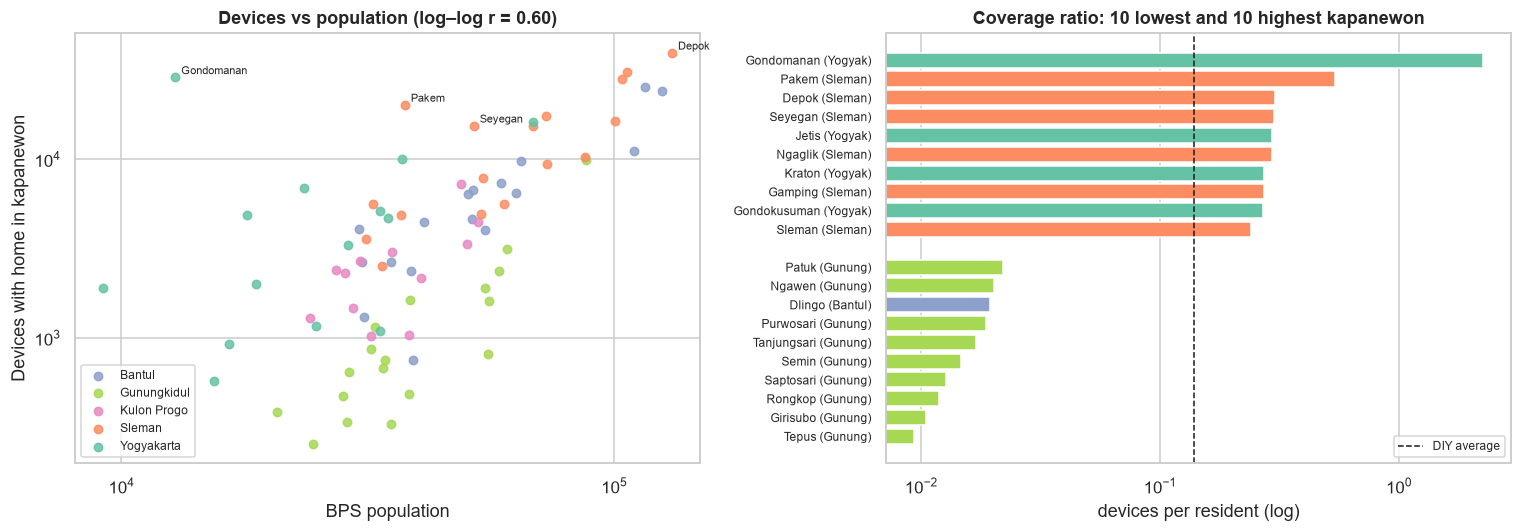

,KAB_KOTA,KEC_KAPN,n_users,pop_actual,ratio
0,YOGYAKARTA,GONDOMANAN,28874,12850.0,2.247004
1,SLEMAN,PAKEM,20241,37580.0,0.538611
2,SLEMAN,DEPOK,39609,130980.0,0.302405
3,SLEMAN,SEYEGAN,15469,51860.0,0.298284
4,YOGYAKARTA,JETIS,6922,23480.0,0.294804


In [19]:
p = pop.copy()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
for kab, g in p.groupby("KAB_KOTA"):
    ax.scatter(g.pop_actual, g.n_users, color=KAB_COLORS[kab], label=kab.title(), s=30, alpha=.85)
lim = [p[["pop_actual", "n_users"]].min().min() * .8, p[["pop_actual", "n_users"]].max().max() * 1.2]
ax.set_xscale("log"); ax.set_yscale("log")
r = np.corrcoef(np.log(p.pop_actual), np.log(p.n_users))[0, 1]
ax.set_xlabel("BPS population"); ax.set_ylabel("Devices with home in kapanewon")
ax.set_title(f"Devices vs population (log–log r = {r:.2f})")
for _, row in p.nlargest(4, "ratio").iterrows():
    ax.annotate(row.KEC_KAPN.title(), (row.pop_actual, row.n_users), fontsize=7, xytext=(4, 2), textcoords="offset points")
ax.legend(fontsize=8)

ax = axes[1]
q = p.sort_values("ratio")
q = pd.concat([q.head(10), q.tail(10)])          # 10 lowest + 10 highest
labels = q.KEC_KAPN.str.title() + " (" + q.KAB_KOTA.str.title().str[:6] + ")"
ypos = list(range(10)) + list(range(11, 21))     # gap between the two groups
ax.barh(ypos, q.ratio, color=q.KAB_KOTA.map(KAB_COLORS))
ax.set_yticks(ypos, labels, fontsize=8)
ax.set_xscale("log")
ax.axvline(p.n_users.sum() / p.pop_actual.sum(), color="k", ls="--", lw=1, label="DIY average")
ax.set_xlabel("devices per resident (log)")
ax.set_title("Coverage ratio: 10 lowest and 10 highest kapanewon")
ax.grid(axis="y", visible=False)
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
savefig(fig, "representativeness")
plt.show()
p.sort_values("ratio", ascending=False).head(5)

Device counts follow population reasonably (log–log r ≈ 0.6), but with big outliers:
- Gondomanan (central city, next to Malioboro and the Kraton) has 2.2 "home" devices per resident. Possible reasons are hotels, boarding houses (kos) and visitors who sleep there but aren't registered residents. Once boundaries are added, check whether a lattice-artifact cell falls inside it.
- Rural Gunungkidul and Kulon Progo kapanewon are under-represented.

So JogjaPulse over-weights the urban core, and per-capita comparisons need care.

## 7. Daytime visit flows (OD, Dec 2021 – Feb 2022 only)
March and April are flagged `reduced_quality` and excluded.

months used: ['2021-12', '2022-01', '2022-02']


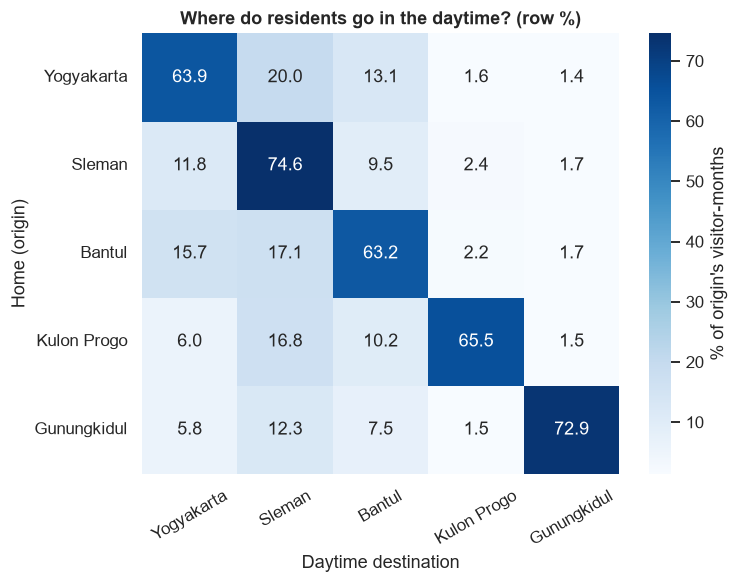

In [20]:
odq = od[~od.reduced_quality]
print("months used:", sorted(odq.month.unique()))
kk = (odq.groupby(["origin_kab_kota", "dest_kab_kota"]).n_maids.sum().unstack()
      .reindex(index=KAB_ORDER, columns=KAB_ORDER))
kk_pct = kk.div(kk.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(7, 5.2))
sns.heatmap(kk_pct, annot=True, fmt=".1f", cmap="Blues", ax=ax, cbar_kws={"label": "% of origin's visitor-months"})
ax.set_xlabel("Daytime destination"); ax.set_ylabel("Home (origin)")
ax.set_title("Where do residents go in the daytime? (row %)")
ax.set_xticklabels([k.title() for k in KAB_ORDER], rotation=30)
ax.set_yticklabels([k.title() for k in KAB_ORDER], rotation=0)
savefig(fig, "od_kabupaten_matrix")
plt.show()

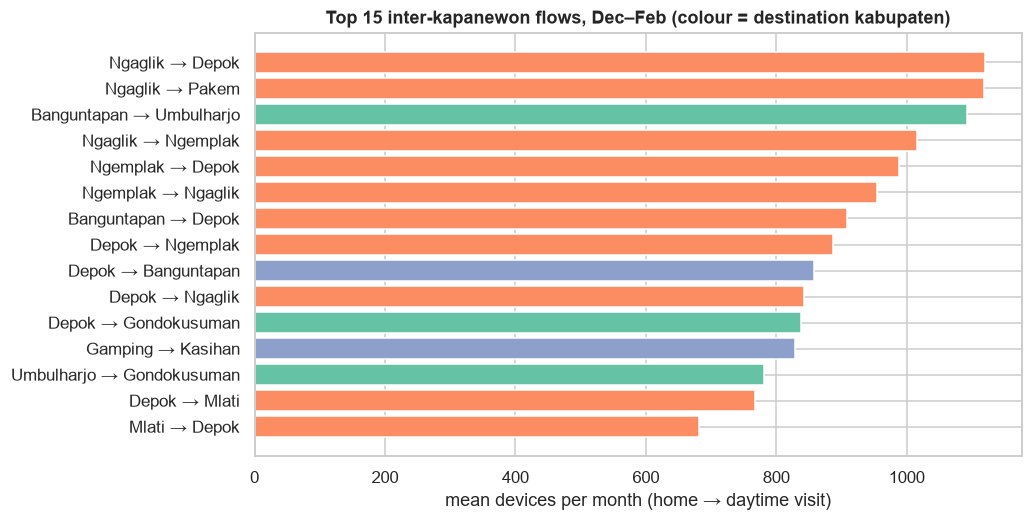

In [21]:
# Compare codes, not names: JETIS exists in both Bantul and Kota Yogyakarta.
inter = odq[odq.origin_code != odq.dest_code]
top_flows = (inter.groupby(["origin_code", "dest_code", "origin_kapanewon", "origin_kab_kota", "dest_kapanewon", "dest_kab_kota"])
             .n_maids.mean().nlargest(15).reset_index())
top_flows["label"] = top_flows.origin_kapanewon.str.title() + " → " + top_flows.dest_kapanewon.str.title()

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top_flows.label[::-1], top_flows.n_maids[::-1],
        color=top_flows.dest_kab_kota[::-1].map(KAB_COLORS))
ax.set_xlabel("mean devices per month (home → daytime visit)")
ax.set_title("Top 15 inter-kapanewon flows, Dec–Feb (colour = destination kabupaten)")
savefig(fig, "od_top_flows")
plt.show()

## 8. Google Community Mobility (DIY)

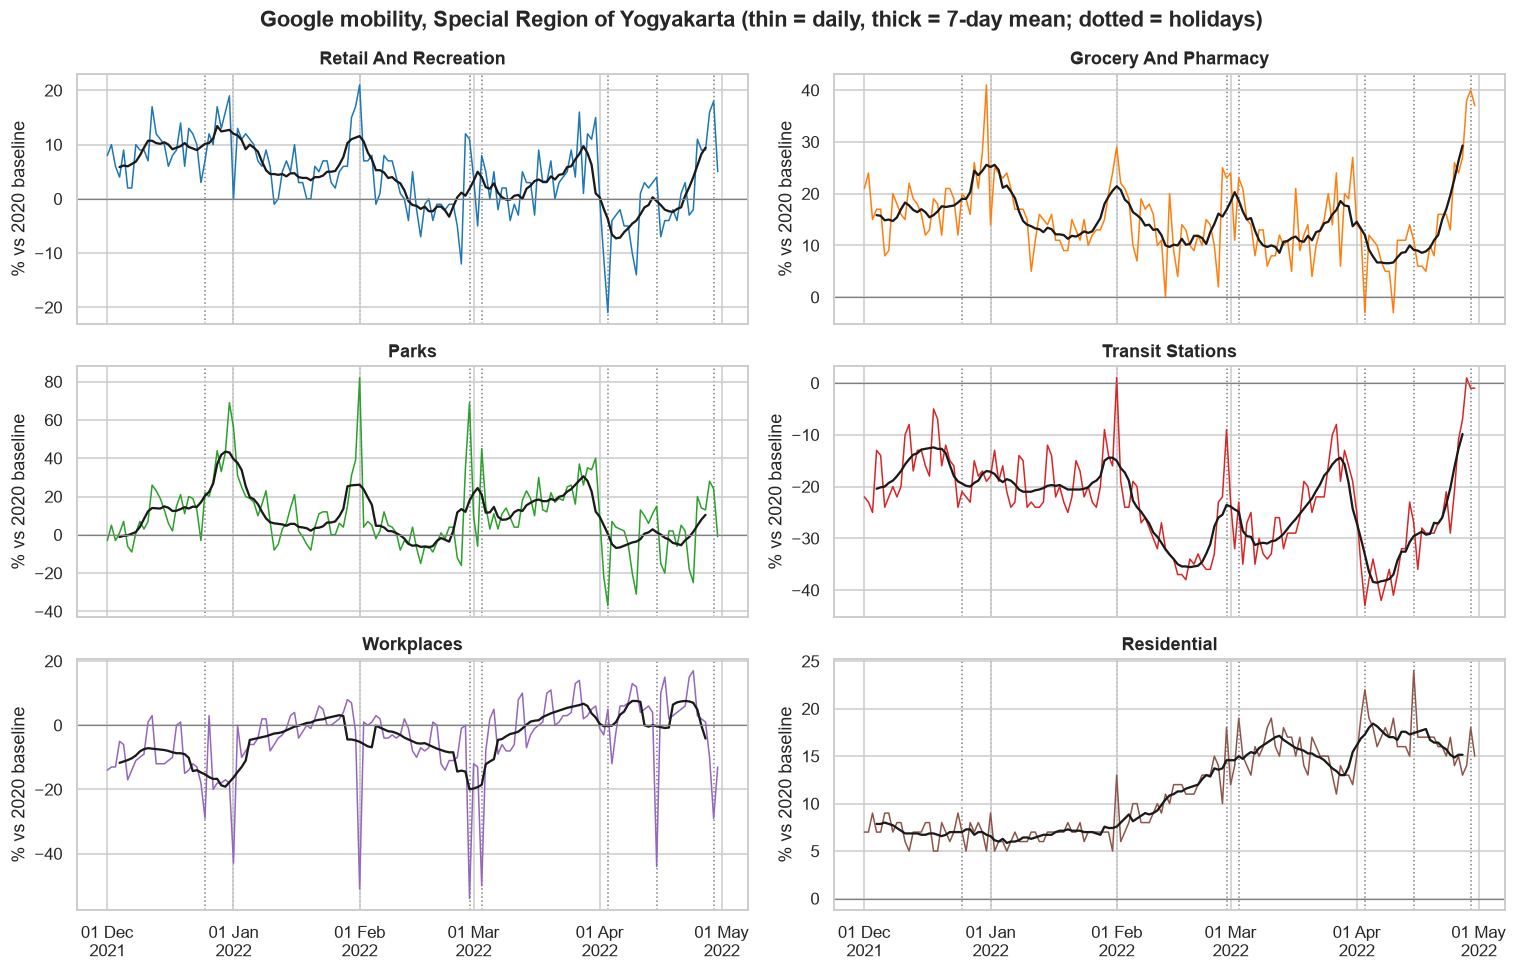

,retail_and_recreation,grocery_and_pharmacy,parks,transit_stations,workplaces,residential
count,151.0,151.0,151.0,151.0,151.0,151.0
mean,4.4,15.1,10.1,-23.1,-4.1,11.3
std,6.9,7.4,17.7,9.1,11.8,4.6
min,-21.0,-3.0,-37.0,-43.0,-54.0,5.0
25%,0.0,10.5,1.0,-29.0,-10.0,7.0
50%,5.0,14.0,7.0,-23.0,-1.0,11.0
75%,9.0,19.5,19.0,-17.0,3.0,15.0
max,21.0,41.0,82.0,1.0,17.0,24.0


In [22]:
fig, axes = plt.subplots(3, 2, figsize=(14, 9), sharex=True)
for ax, cat, col in zip(axes.flat, GCATS, sns.color_palette("tab10", 6)):
    s = google.set_index("date")[cat]
    ax.plot(s.index, s, color=col, lw=1)
    ax.plot(s.index, s.rolling(7, center=True).mean(), color="k", lw=1.5)
    ax.axhline(0, color="grey", lw=.8)
    ax.set_title(cat.replace("_", " ").title())
    ax.set_ylabel("% vs 2020 baseline")
    mark_events(ax, breaks=False, labels=False)
fig.suptitle("Google mobility, Special Region of Yogyakarta (thin = daily, thick = 7-day mean; dotted = holidays)",
             fontweight="bold")
fig.tight_layout()
savefig(fig, "google_categories")
plt.show()
google[GCATS].describe().round(1)

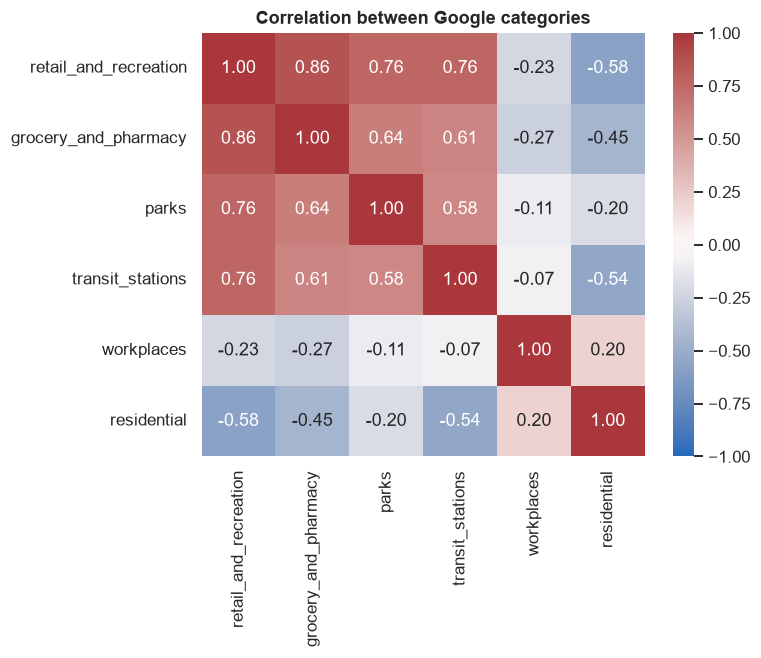

In [23]:
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(google[GCATS].corr(method="spearman"), annot=True, fmt=".2f", cmap="vlag",
            vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation between Google categories")
savefig(fig, "google_corr")
plt.show()

## 9. First look: JogjaPulse vs Google

The two sources are collected and processed independently, so agreement between them counts as external validation.

Pitfall: raw JogjaPulse totals fall with the panel while Google's residential rises, so the raw correlation is large but meaningless.

Method: compare the deviation from the same weekday in both sources (median of the same weekday 1 and 2 weeks before and after, leaving out the day itself and holidays; `build_features.weekday_deviation`, the same function notebook 02 uses). Use a log ratio for JogjaPulse shares and a difference for Google's percentages.

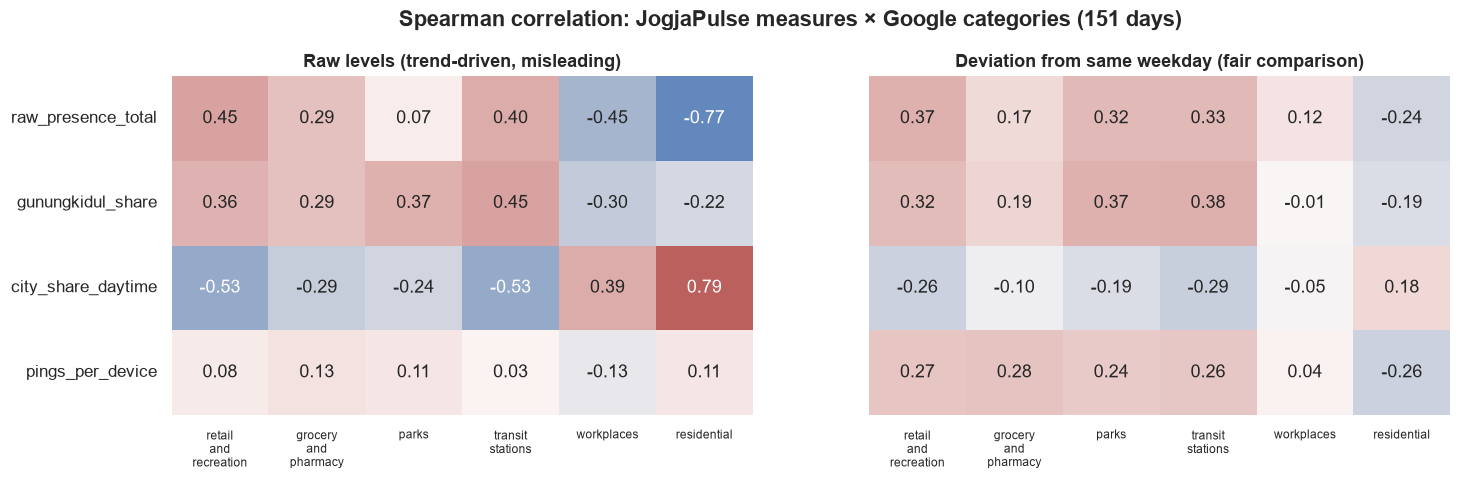

In [24]:
holidays = CAL_D.is_holiday

jp = pd.DataFrame({
    "raw_presence_total": daily.presence_total,
    "gunungkidul_share": kab_share["GUNUNGKIDUL"],
    "city_share_daytime": (hourly[(hourly.kab_kota == "YOGYAKARTA") & hourly.hour.between(9, 17)]
                           .groupby("date").n_maids.sum()
                           / hourly[hourly.hour.between(9, 17)].groupby("date").n_maids.sum()),
    "pings_per_device": daily.pings_per_device,
})
G = google.set_index("date")[GCATS]

raw_corr = jp.join(G).corr(method="spearman").loc[jp.columns, GCATS]
adj = weekday_deviation(jp, True, holidays).join(weekday_deviation(G, False, holidays)).dropna()
adj_corr = adj.corr(method="spearman").loc[jp.columns, GCATS]

fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for ax, c, title in [(axes[0], raw_corr, "Raw levels (trend-driven, misleading)"),
                     (axes[1], adj_corr, "Deviation from same weekday (fair comparison)")]:
    sns.heatmap(c, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, ax=ax, cbar=False)
    ax.set_title(title)
    ax.set_xticklabels([x.replace("_", "\n") for x in GCATS], rotation=0, fontsize=8)
fig.suptitle("Spearman correlation: JogjaPulse measures × Google categories (151 days)", fontweight="bold", y=1.03)
savefig(fig, "jp_vs_google_corr")
plt.show()

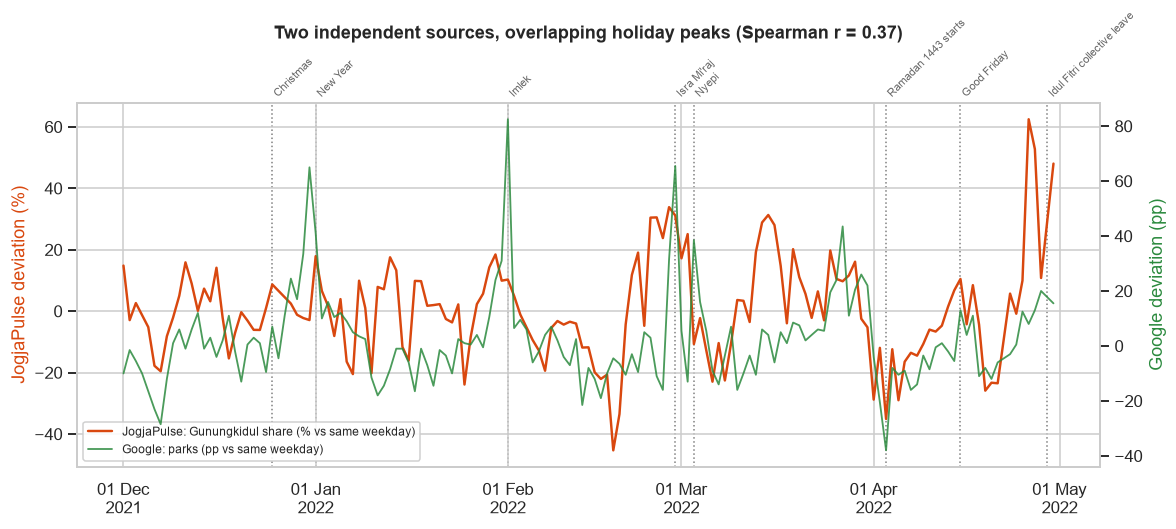

In [25]:
JP_COL, G_COL = "#d9480f", "#2b8a3e"
fig, ax1 = plt.subplots(figsize=(12, 4.3))
ax1.plot(adj.index, adj.gunungkidul_share * 100, color=JP_COL, lw=1.6,
         label="JogjaPulse: Gunungkidul share (% vs same weekday)")
ax1.set_ylabel("JogjaPulse deviation (%)", color=JP_COL)
ax2 = ax1.twinx()
ax2.plot(adj.index, adj.parks, color=G_COL, lw=1.2, alpha=.85, label="Google: parks (pp vs same weekday)")
ax2.set_ylabel("Google deviation (pp)", color=G_COL)
ax2.grid(False)
mark_events(ax1, breaks=False)
r = adj[["gunungkidul_share", "parks"]].corr(method="spearman").iloc[0, 1]
ax1.set_title(f"Two independent sources, overlapping holiday peaks (Spearman r = {r:.2f})", pad=42)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="lower left", fontsize=8, framealpha=.9)
savefig(fig, "jp_vs_google_parks")
plt.show()

## 10. Key takeaways

In [26]:
summary = {
    "Days covered (both sources)": hourly.date.nunique(),
    "Kapanewon in hourly file (by code)": hourly.kapanewon_code.nunique(),
    "Night presence, peak month mean": int(monthly.max()),
    "Night presence, Apr 2022 mean": int(monthly.iloc[-1]),
    "Peak / April ratio": round(shrink, 1),
    "Kota Yogyakarta share, Dec → Apr (%)": f"{100*kab_share.YOGYAKARTA[:31].mean():.0f} → {100*kab_share.YOGYAKARTA[-30:].mean():.0f}",
    "Grid presence lost to suppression (%)": float(tier1.loc[0, "maid_presence_suppressed_pct"]),
    "Presence in lattice-artifact cells (%)": round(100 * cells.loc[cells.lattice_artifact, "mean_share"].sum(), 1),
    "Devices vs population, log-log r": round(np.corrcoef(np.log(pop.pop_actual), np.log(pop.n_users))[0, 1], 2),
    "JP Gunungkidul share vs Google parks (adjusted r)": round(adj_corr.loc["gunungkidul_share", "parks"], 2),
    "JP raw total vs Google residential (raw r, spurious)": round(raw_corr.loc["raw_presence_total", "residential"], 2),
}
pd.Series(summary).astype(str).to_frame("value")

,value
Days covered (both sources),151
Kapanewon in hourly file (by code),78
"Night presence, peak month mean",3723
"Night presence, Apr 2022 mean",644
Peak / April ratio,5.8
"Kota Yogyakarta share, Dec → Apr (%)",11 → 25
Grid presence lost to suppression (%),6.6
Presence in lattice-artifact cells (%),8.6
"Devices vs population, log-log r",0.6
JP Gunungkidul share vs Google parks (adjusted r),0.37


| # | Takeaway | Consequence for the project |
|---|---|---|
| 1 | Panel size is unstable. Night presence peaks in February, then collapses after 16 Feb (README panel break). | Never compare raw counts over time. |
| 2 | The panel's geography drifts. Kota Yogyakarta's share more than doubles from Dec to Apr. | Shares alone aren't enough over time: use a same-weekday local baseline or compare within panel segments. |
| 3 | Coordinate-lattice artifact: 1.2% of grid cells (on 0.1°/0.05° points) hold 8.6% of presence. | Drop `lattice_artifact` cells in grid analyses (notebook 04); mention it in the video's limitations. |
| 4 | Kapanewon names are not unique (78 codes, 77 names; JETIS appears twice). | Join on code or (kabupaten, name). |
| 5 | Suppression removes 0.7% of presence (hourly), 6.6% (grid). Rural Gunungkidul kapanewon are published in only 20–50% of hours. | Rural hourly analysis is noisy; aggregate rural areas. |
| 6 | Devices follow population (log–log r = 0.60) but over-weight the urban core (Gondomanan ratio > 2). | Per-capita results need a caveat. |
| 7 | Activity is low 02–05, flat from about 11 to 17, and peaks 18–20. Weekends and holidays raise Gunungkidul's share. | Input for notebooks 03 and 04. Notebook 04 later found single-day cell shifts on holidays to be within ordinary-weekend noise. |
| 8 | JogjaPulse Gunungkidul share vs Google parks: Spearman r = 0.37 after the weekday adjustment (same function as notebook 02). The raw −0.77 is a different pair (total device-hours vs residential) and comes from the shared trend. | Weak-to-moderate agreement; notebook 02 adds confidence intervals and the other pairs. |